In [3]:
import matplotlib.pyplot as plt
import numpy as np
#%matplotlib widget

In [4]:
class VCO:
    def __init__(self, freq0, t0=None, phase_jitter=0, drift_rate=0, Vrange=(0, 1), Vscale=0.01):
        self.freq0 = freq0
        self._freq_offset = 0.0
        self.Vrange = Vrange
        self._Vmid = (Vrange[0] + Vrange[1]) / 2
        self.V = self._Vmid
        self.Vscale = Vscale
        self.dt0 = 1 / self.freq0
        self.phase_jitter = phase_jitter  # fractional
        self.drift_rate = drift_rate # Hz / s
        if t0 is None:
            self.set_t(-self.dt0)
        else:
            self.set_t(t0)

    def _update_freq(self):
        self._freq = self.freq0 * (1 + self.Vscale * (self.V - self._Vmid) / (self.Vrange[1] - self.Vrange[0]))

    def set_t(self, t):
        self.t = t

    def get_freqs(self, n):
        self._update_freq()
        fq_offsets = self._freq_offset + np.cumsum(np.random.normal(size=n) * self.dt0 * self.drift_rate)
        fq_drift = self._freq + fq_offsets
        self._freq_offset = fq_offsets[-1]
        self.freq = fq_drift[-1]
        return fq_drift

    def get_ts(self, n):
        fq_drift = self.get_freqs(n)
        dt_drift = 1 / fq_drift
        dt_jitter = dt_drift * (1 + np.random.normal(size=n) * self.phase_jitter * self.dt0)
        ts = self.t + np.cumsum(dt_jitter)
        self.set_t(ts[-1])
        return ts

    def set_voltage(self, V):
        self.V = V

class Oscillator:
    def __init__(self, freq, amp=1.0, phase=0.0):
        self.freq = freq
        self.amp = amp
        self.phase = phase

    def sample(self, ts):
        return self.amp * np.exp(1j * (2 * np.pi * self.freq * ts + self.phase))

class PLLController:
    def __init__(self, t_update, buflen=3):
        self.t_update = t_update   # time between updates (block length in seconds)

        self.phserr = [0 for i in buflen]
        self.df_est = [0 for i in buflen]

    def update(self, phase_err):
        # Integral of phase error
        self.prev.insert(0, phase_err)
        self.prev.pop()
        self.prev.i
        self.int_err += phase_err * self.t_update

        # Derivative of phase error
        d_err = (phase_err - self.prev_err) / self.t_update
        self.prev_err = phase_err

        # Loop filter: df is a *change* to the correction estimate
        d_df = (self.Kp * phase_err
                + self.Ki * self.int_err
                + self.Kd * d_err)

        self.df_est += d_df
        return self.df_est

In [5]:
np.random.seed(0)
f_sample = 1e8
#nsamp = 2048
nsamp = 512
t_block = nsamp / f_sample  # seconds per control update

vco = VCO(f_sample, drift_rate=3e7)
vco_mdl = VCO(f_sample)
initial_phase_rad = 0.5
osc_meas = Oscillator(15e6, phase=initial_phase_rad)
osc_ref = Oscillator(15e6)

noise_lev = 0.0

N = 256
mix_sum = []
buf = []
Vscale = 0.01
Vrange = (0, 1)
Vmid = 0.5
gain = 1.0
for i in range(64*N*2048 // nsamp):
    # measurement
    ts = vco.get_ts(nsamp)
    sig = osc_meas.sample(ts).real + noise_lev * np.random.normal(size=nsamp)
    # model
    ts_mdl = vco_mdl.get_ts(nsamp)
    sig_mdl = osc_ref.sample(ts_mdl)

    mix = np.mean(sig * sig_mdl.conj())
    dphs = np.angle(mix) / (2 * np.pi)
    frac = dphs / nsamp
    V = gain * frac / Vscale * (Vrange[1] - Vrange[0]) + Vmid
    #V = Vmid
    buf.append((ts[-1] - ts_mdl[-1], vco.freq - vco.freq0, V))
    vco.set_voltage(V)

    mix_sum.append(mix)
mix_sum = np.asarray(mix_sum)

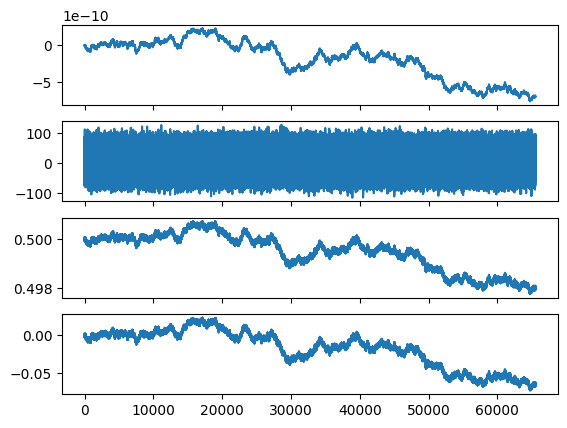

In [6]:
fig, axes = plt.subplots(nrows=4, sharex=True, figsize=(10, 8))
buf = np.asarray(buf)
phase_err_rad = np.angle(mix_sum)
axes[0].plot(buf[:, 0])
axes[0].set_ylabel('time skew (s)')
axes[1].plot(buf[:, 1])
axes[1].set_ylabel('freq err (Hz)')
axes[2].plot(buf[:, 2])
axes[2].set_ylabel('ctrl V')
axes[3].plot(phase_err_rad)
axes[3].axhline(initial_phase_rad, color='tab:red', linestyle='--', alpha=0.6)
axes[3].set_ylabel('mix phase (rad)')
axes[3].set_xlabel('update')
fig.suptitle(f'clock_sync_simulation with initial phase offset = {initial_phase_rad:.1f} rad')
fig.tight_layout()
None

In [ ]:
summary = {
    'initial_phase_rad': float(initial_phase_rad),
    'first_mix_phase_rad': float(phase_err_rad[0]),
    'mean_mix_phase_first_128_updates_rad': float(np.mean(phase_err_rad[:128])),
    'mean_mix_phase_last_128_updates_rad': float(np.mean(phase_err_rad[-128:])),
    'final_time_skew_s': float(buf[-1, 0]),
    'final_freq_error_hz': float(buf[-1, 1]),
    'final_control_voltage': float(buf[-1, 2]),
}
summary